In [1]:
import pandas as pd
import tensorflow as tf
import numpy as np

2026-11-10 01:27:25.151622: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-10 01:27:25.211749: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
# gpus = tf.config.list_physical_devices('GPU')
# if gpus:
#     print(f"GPU is AVAILABLE. Found {len(gpus)} GPU(s).")
#     for gpu in gpus:
#         tf.config.experimental.set_memory_growth(gpu, True)


In [3]:
# Hide all GPU devices
tf.config.set_visible_devices([], "GPU")

# Verify
print(tf.config.list_physical_devices("CPU"))

[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [4]:
org_df = pd.read_csv('en-fr.csv'
                 #sep='\t',
                 #header=None,
                 #usecols=[0,1],
                 #names=['English','French']
                )

In [5]:
org_df.shape

(22520376, 2)

In [6]:
df = org_df.iloc[:10000].copy()

In [7]:

# Remove missing and duplicate sentence pairs
#df = df.isnull().sum()
#org_df = org_df.drop_duplicates(subset=['en', 'fr'], inplace=True)



In [8]:
df.shape

(10000, 2)

In [9]:

# Calculate sentence lengths
df['eng_length'] = df['en'].str.split().str.len()
df['fre_length'] =  df['fr'].str.split().str.len()

In [10]:

# Select sentences with maximum 20 words in both languages
df = df[
    (df['eng_length'] <= 100) &
    (df['fre_length'] <= 100)
].copy()

df.reset_index(drop=True, inplace=True)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (9956, 4)


,en,fr,eng_length,fre_length
0,Changing Lives | Changing Society | How It Wor...,Il a transformé notre vie | Il a transformé la...,37.0,42
1,Site map,Plan du site,2.0,3
2,Feedback,Rétroaction,1.0,1
3,Credits,Crédits,1.0,1
4,Français,English,1.0,1


In [11]:
#df  = org_df.copy()
#df  = df.iloc[:100000].copy()
#df.shape

In [12]:
## Add start and end tokens
df['fr'] = df['fr'].apply(lambda x : '<sos> ' + x.strip() + ' <eos>')

'''
Original:
Bonjour mon ami.

After adding tokens:
<sos> Bonjour mon ami. <eos>

During inference, the decoder starts with <sos> and predicts subsequent words until it generates <eos>
'''
df['fr'].head()

0    <sos> Il a transformé notre vie | Il a transfo...
1                             <sos> Plan du site <eos>
2                              <sos> Rétroaction <eos>
3                                  <sos> Crédits <eos>
4                                  <sos> English <eos>
Name: fr, dtype: str

In [13]:
df

,en,fr,eng_length,fre_length
0,Changing Lives | Changing Society | How It Wor...,<sos> Il a transformé notre vie | Il a transfo...,37.0,42
1,Site map,<sos> Plan du site <eos>,2.0,3
2,Feedback,<sos> Rétroaction <eos>,1.0,1
3,Credits,<sos> Crédits <eos>,1.0,1
4,Français,<sos> English <eos>,1.0,1
...,...,...,...,...
9951,"As laid down under Section 9, of the Public He...",<sos> Aux termes de l'article 9 de la Loi de 1...,31.0,34
9952,FOOD LABELLING REQUIREMENT Pre-packed foods so...,<sos> EXIGENCES EN MATIÈRE D'ÉTIQUETAGE Les al...,28.0,37
9953,Language to be used on the label should be in ...,<sos> Les renseignements sur l'étiquette doive...,21.0,29
9954,"Generally, the particulars of the labelling re...","<sos> Normalement, les renseignements exigés s...",9.0,8


In [14]:
tf.keras.backend.clear_session()

In [15]:
from tensorflow.keras.preprocessing.text import  Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [16]:
eng_tokenizer = Tokenizer(filters="", oov_token="<OOV>") #filters="" means we don't want to filter out any characters, oov_token="<OOV>" means we want to use <OOV> for out-of-vocabulary words
fre_tokenizer = Tokenizer(filters="", oov_token="<OOV>") #filters="" means we don't want to filter out any characters, oov_token="<OOV>" means we want to use <OOV> for out-of-vocabulary words

In [17]:
eng_tokenizer.fit_on_texts(df['en'])
## Reads all the English sentence and builds a vocabulary

## I am happy , I am learning , I am fine. -> I am happy learning fine

eng_tokenizer.word_index # 0 is reserved for padding, so the index starts from 1

{'<OOV>': 1,
 'the': 2,
 'of': 3,
 'and': 4,
 'in': 5,
 'to': 6,
 'a': 7,
 'is': 8,
 'for': 9,
 'are': 10,
 'that': 11,
 'as': 12,
 'with': 13,
 'on': 14,
 'from': 15,
 'by': 16,
 'at': 17,
 'this': 18,
 'canadian': 19,
 'be': 20,
 'was': 21,
 'food': 22,
 'an': 23,
 'has': 24,
 'it': 25,
 'or': 26,
 ':': 27,
 'canada': 28,
 'market': 29,
 'have': 30,
 'he': 31,
 'its': 32,
 'trade': 33,
 '•': 34,
 'products': 35,
 'which': 36,
 'more': 37,
 'their': 38,
 'also': 39,
 'not': 40,
 'million': 41,
 'will': 42,
 '-': 43,
 'other': 44,
 'light': 45,
 'first': 46,
 'his': 47,
 'were': 48,
 'all': 49,
 'exports': 50,
 'new': 51,
 'agri-food': 52,
 'than': 53,
 'one': 54,
 'israel': 55,
 'international': 56,
 'over': 57,
 'imports': 58,
 'these': 59,
 'observatory': 60,
 'most': 61,
 'meat': 62,
 'can': 63,
 'been': 64,
 'government': 65,
 'growth': 66,
 'about': 67,
 'there': 68,
 'research': 69,
 'population': 70,
 'industry': 71,
 'into': 72,
 'information': 73,
 'agricultural': 74,
 'but':

In [18]:
## Converting text into numerical sequence

encoder_input = eng_tokenizer.texts_to_sequences(df['en'])

''' {
'i' : 1,
'am' : 2,
'learning' : 3
}

i am learning --> [1,2,3]
'''
encoder_input

[[2479,
  2480,
  1888,
  2479,
  524,
  1888,
  386,
  25,
  2036,
  1888,
  421,
  10093,
  750,
  491,
  1888,
  6697,
  1888,
  3154,
  1888,
  1501,
  1888,
  368,
  1888,
  3155,
  1888,
  10094,
  601,
  1888,
  1337,
  1888,
  4259,
  2037,
  4260,
  3,
  28,
  491,
  1889],
 [422, 270],
 [4259],
 [3155],
 [6698],
 [221, 8, 45, 3626],
 [2,
  359,
  45,
  423,
  3156,
  5,
  2,
  45,
  2,
  711,
  423,
  1414,
  1415,
  3157,
  1415,
  1502,
  45,
  712],
 [2, 285, 3, 2, 46, 5219, 7, 3627, 5220, 3, 2, 313, 136, 9, 4261],
 [6699],
 [1338],
 [4262],
 [195],
 [91, 644, 644, 751, 221, 8, 6700],
 [566,
  625,
  2,
  3158,
  2249,
  25,
  21,
  713,
  3,
  118,
  10095,
  17,
  2,
  285,
  4,
  118,
  538,
  6,
  1890,
  136,
  8,
  2,
  881,
  3,
  197,
  1616,
  1339,
  2250],
 [2,
  424,
  8,
  2788,
  15,
  2,
  3159,
  4263,
  10096,
  9,
  1416,
  4,
  10097,
  9,
  3160,
  26,
  6701],
 [136,
  8,
  6702,
  13,
  369,
  1018,
  4,
  10098,
  77,
  171,
  714,
  1503,
  2038,
  

In [19]:
fre_tokenizer.fit_on_texts(df['fr'])

In [20]:
decoder_input = fre_tokenizer.texts_to_sequences(
    df['fr']
)

In [21]:
max_len_eng = max(len(x) for x in encoder_input)
max_len_fre = max(len(x) for x in decoder_input)
#max_len_eng = 60
#max_len_fre = 60

## Finding the longest sentence in each language
'''
sen1 = [1,2,3]  -->length = 3
sen2 = [4,5]     -->length = 2
sen3 = [6,7,8,9] -->length = 4
max_len = 4
'''
print(max_len_eng, max_len_fre)

93 102


In [22]:
# Padding to make same length sequences
from tensorflow.keras.preprocessing.sequence import pad_sequences
'''
sen1 = [1,2,3]  to [1,2,3,0]
sen2 = [4,5]     to [4,5,0,0]
sen3 = [6,7,8,9] to [6,7,8,9]
'''
encoder_input = pad_sequences(encoder_input,max_len_eng,padding='post') # zeros at the end

decoder_input = pad_sequences(decoder_input,max_len_fre,padding='post') # zeros at the end

encoder_input



array([[ 2479,  2480,  1888, ...,     0,     0,     0],
       [  422,   270,     0, ...,     0,     0,     0],
       [ 4259,     0,     0, ...,     0,     0,     0],
       ...,
       [ 1828,     6,    20, ...,     0,     0,     0],
       [ 4947,     2, 22702, ...,     0,     0,     0],
       [   34,   424,     3, ...,     0,     0,     0]], dtype=int32)

In [23]:
decoder_target = [] # create an empty list to store the target sequence


''' e.g. decoder is ecpected to predict je suis heureux <eos>, This is called teacher forcing during training.
<sos> je suis heureux <eos>
decoder_input = [1, 2, 3, 4, 5]
decoder_target = [2, 3, 4, 5]
'''


for seq in decoder_input:
    decoder_target.append(seq[1:])  # keep everything except <sos>

decoder_target = pad_sequences(
    decoder_target,
    maxlen=max_len_fre,
    padding='post'
)
    
decoder_target    

'''here is one additional consideration: padded target positions should not contribute to the loss function.
We will handle that during training.'''
    

'here is one additional consideration: padded target positions should not contribute to the loss function.\nWe will handle that during training.'

In [24]:
# Calculate vocabulary length
eng_vocab_size = len(eng_tokenizer.word_index) + 1
fre_vocab_size = len(fre_tokenizer.word_index) + 1

'''
Why do we add 1?

Because index 0 is reserved for padding.
0 → Padding
1 → I
2 → am
3 → happy

'''
print(eng_vocab_size, fre_vocab_size)
#These vocabulary sizes will determine the dimensions of the embedding and output layers.

22704 26130


In [25]:
from tensorflow.keras.layers import Input, LSTM, Embedding, Dense
from tensorflow.keras.models import Model

In [26]:
# Embedding -> vector representation of words
'''
I am learning -> [1,2,3] -> [[0.1,0.2,0.3],[0.4,0.5,0.6],[0.7,0.8,0.9]]  (3 words, each represented by a 3-dimensional vector)
'''
encoder_inputs =Input(shape=(max_len_eng,),
                      name = 'encoder_input_layer')

enc_emb = Embedding(
    eng_vocab_size,
    128,
    mask_zero=True, # the LSTM can ignore padded input positions.,
    name = 'encoder_embedding_layer'
    
)(encoder_inputs)

enc_emb.shape

(None, 93, 128)

Suppose
- Batch size = 100
- Maximum English sentence length = 10
- Embedding dimension = 512
The encoder input has shape:
\[
(100,10)
\]

After embedding:
\[
(100,10,512)
\]

What does this mean?

Each word is converted into a 512-dimensional vector.

For example

I       → [0.21, 0.32, ..., 0.15] \
am      → [0.13, 0.42, ..., 0.27] \
happy   → [0.54, 0.19, ..., 0.31] 

In [27]:
# Lets create Dense LSTM with 2 layers of LSTM

from keras.src.layers import LSTM


# LSTM layer 1
enc_lstm1 = LSTM(128,
                return_state=True, # return_state=True means we want to get the hidden and cell states of the LSTM
                return_sequences=True, # since we also need the output 
                dropout=0.2, #regularization to prevent overfitting
                name = 'encoder_lstm_layer1')

# get the output and states from the first LSTM layer
enc_output1, enc_h1, enc_c1 = enc_lstm1(enc_emb)

print(enc_output1.shape, enc_h1.shape, enc_c1.shape)


# LSTM layer 2 (Here we do not need the return_sequences=True because we only need the final output and states from the second LSTM layer)
enc_lstm2 = LSTM(128,
                return_state=True, # return_state=True means we want to get the hidden and cell states of the LSTM 
                dropout=0.2, #regularization to prevent overfitting
                name = 'encoder_lstm_layer2')    

# get the output and states from the second LSTM layer , the iput is the o/p of the first LSTM layer
enc_output2, enc_h2, enc_c2 = enc_lstm2(enc_output1) 

print(enc_output2.shape, enc_h2.shape, enc_c2.shape)

# Collect encoder states
encoder_states = [
    enc_h1, enc_c1,
    enc_h2, enc_c2
]

(None, 93, 128) (None, 128) (None, 128)
(None, 128) (None, 128) (None, 128)


In [28]:
# Decoder Architecture
decoder_inputs = Input(shape=(max_len_fre,),
                       name = 'decoder_input_layer')

dec_emb = Embedding(
    fre_vocab_size,
    128,
    mask_zero=True,
    name = 'decoder_embedding_layer'
)(decoder_inputs)

print(dec_emb.shape)


dec_lstm1 = LSTM(128, 
                return_sequences=True, # Returns the output at every time step
                return_state=True, #Returns the final hidden and cell states,
                name = 'decoder_lstm_layer1'
)

decoder_output1, _, _ = dec_lstm1(
    dec_emb,
    initial_state=[enc_h1, enc_c1] # the corresponding hidden and cell states from the encoder's first LSTM layer are used to initialize the decoder's first LSTM layer
)


dec_lstm2 = LSTM(128, 
                return_sequences=True, # Returns the output at every time step
                return_state=True, #Returns the final hidden and cell states,
                name = 'decoder_lstm_layer2'
)

decoder_output2, _, _ = dec_lstm2(
    decoder_output1, # the output from the first decoder LSTM layer is used as input to the second decoder LSTM layer
    initial_state=[enc_h2, enc_c2] # the corresponding hidden and cell states from the encoder's second LSTM layer are used to initialize the decoder's second LSTM layer
)



print(decoder_output1.shape, decoder_output2.shape)

(None, 102, 128)
(None, 102, 128) (None, 102, 128)


In [29]:
# Dense layer to generate predictions for each time step with softmax
decoder_dense = Dense(
    fre_vocab_size, 
    activation = 'softmax'
)
decoder_probability_output = decoder_dense(decoder_output2) # passed the decoder output to the dense layer to get the probability distribution over the French vocabulary for each time step
decoder_probability_output.shape

(None, 102, 26130)

In [30]:
# Complete model
model = Model(
    [encoder_inputs, decoder_inputs],
    decoder_probability_output
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input_layer │ (None, 93)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_input_layer │ (None, 102)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_embedding_… │ (None, 93, 128)   │  2,906,112 │ encoder_input_la… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 93)        │          0 │ encoder_input_la… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_embedding_… │ (None, 102, 128)  │  3,344,640 │ decoder_input_la… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_lstm_layer1 │ [(None, 93, 128), │    131,584 │ encoder_embeddin… │
│ (LSTM)              │ (None, 128),      │            │ not_equal[0][0]   │
│                     │ (None, 128)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm_layer1 │ [(None, 102,      │    131,584 │ decoder_embeddin… │
│ (LSTM)              │ 128), (None,      │            │ encoder_lstm_lay… │
│                     │ 128), (None,      │            │ encoder_lstm_lay… │
│                     │ 128)]             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_lstm_layer2 │ [(None, 128),     │    131,584 │ encoder_lstm_lay… │
│ (LSTM)              │ (None, 128),      │            │ not_equal[0][0]   │
│                     │ (None, 128)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm_layer2 │ [(None, 102,      │    131,584 │ decoder_lstm_lay… │
│ (LSTM)              │ 128), (None,      │            │ encoder_lstm_lay… │
│                     │ 128), (None,      │            │ encoder_lstm_lay… │
│                     │ 128)]             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 102,       │  3,370,770 │ decoder_lstm_lay… │
│                     │ 26130)            │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 10,147,858 (38.71 MB)

 Trainable params: 10,147,858 (38.71 MB)

 Non-trainable params: 0 (0.00 B)

In [31]:
model.compile(
    optimizer='adam', # updates the 
    loss='sparse_categorical_crossentropy', # sparse_categorical_crossentropy is used when the target labels are integers (not one-hot encoded)
    metrics=['accuracy']
)

In [32]:
encoder_input_data = encoder_input
decoder_input_data = decoder_input
decoder_target_data = decoder_target

sample_weights = (
    decoder_target_data != 0
).astype('float32')

print("Encoder input:", encoder_input_data.shape)
print("Decoder input:", decoder_input_data.shape)
print("Decoder target:", decoder_target_data.shape)
print("Sample weights:", sample_weights.shape)

Encoder input: (9956, 93)
Decoder input: (9956, 102)
Decoder target: (9956, 102)
Sample weights: (9956, 102)


In [33]:
print("Model output:", model.output_shape)
print("French vocabulary:", fre_vocab_size)
print("Target shape:", decoder_target_data.shape)

Model output: (None, 102, 26130)
French vocabulary: 26130
Target shape: (9956, 102)


In [34]:
print("English vocabulary:", eng_vocab_size)
print("French vocabulary:", fre_vocab_size)

print("Encoder input shape:", encoder_input_data.shape)
print("Decoder input shape:", decoder_input_data.shape)

English vocabulary: 22704
French vocabulary: 26130
Encoder input shape: (9956, 93)
Decoder input shape: (9956, 102)


In [35]:
epochs = 20
history = model.fit(
    [encoder_input_data, decoder_input_data],
    decoder_target_data,
    batch_size=64, # 10000/32 FOR LARGE MODELS PEOPLE USE 8
    epochs=10,
    validation_split=0.2
)

Epoch 1/10


2026-11-10 01:29:06.388727: I external/local_xla/xla/service/service.cc:163] XLA service 0x7f947c787b80 initialized for platform Host (this does not guarantee that XLA will be used). Devices:
2026-11-10 01:29:06.388753: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): Host, Default Version
2026-11-10 01:29:06.513900: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-11-10 01:29:06.963705: W tensorflow/compiler/tf2xla/kernels/assert_op.cc:39] Ignoring Assert operator compile_loss/sparse_categorical_crossentropy/SparseSoftmaxCrossEntropyWithLogits/assert_equal_1/Assert/Assert
I0000 00:00:1794254348.148693  194711 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


124/125 ━━━━━━━━━━━━━━━━━━━━ 1s 2s/step - accuracy: 0.0539 - loss: 8.6648

2026-11-10 01:32:47.805546: W tensorflow/compiler/tf2xla/kernels/assert_op.cc:39] Ignoring Assert operator compile_loss/sparse_categorical_crossentropy/SparseSoftmaxCrossEntropyWithLogits/assert_equal_1/Assert/Assert


125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.0540 - loss: 8.6584

2026-11-10 01:32:54.045019: W tensorflow/compiler/tf2xla/kernels/assert_op.cc:39] Ignoring Assert operator compile_loss/sparse_categorical_crossentropy/SparseSoftmaxCrossEntropyWithLogits/assert_equal_1/Assert/Assert
2026-11-10 01:33:25.344558: W tensorflow/compiler/tf2xla/kernels/assert_op.cc:39] Ignoring Assert operator compile_loss/sparse_categorical_crossentropy/SparseSoftmaxCrossEntropyWithLogits/assert_equal_1/Assert/Assert


125/125 ━━━━━━━━━━━━━━━━━━━━ 263s 2s/step - accuracy: 0.0584 - loss: 7.8672 - val_accuracy: 0.0806 - val_loss: 7.5131
Epoch 2/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 242s 2s/step - accuracy: 0.0877 - loss: 7.1740 - val_accuracy: 0.0802 - val_loss: 7.5721
Epoch 3/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 243s 2s/step - accuracy: 0.0898 - loss: 7.0933 - val_accuracy: 0.0804 - val_loss: 7.5822
Epoch 4/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 243s 2s/step - accuracy: 0.0935 - loss: 7.0382 - val_accuracy: 0.0821 - val_loss: 7.5870
Epoch 5/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 242s 2s/step - accuracy: 0.1174 - loss: 6.9200 - val_accuracy: 0.1193 - val_loss: 7.3736
Epoch 6/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 243s 2s/step - accuracy: 0.1457 - loss: 6.6435 - val_accuracy: 0.1263 - val_loss: 7.2855
Epoch 7/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 243s 2s/step - accuracy: 0.1514 - loss: 6.4321 - val_accuracy: 0.1309 - val_loss: 7.2024
Epoch 8/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 243s 2s/step - accuracy: 0.1566 - loss: 6.2512 - val_accuracy: 0.132

In [36]:
train_accuracy = history.history['accuracy'][-1]
validation_accuracy = history.history['val_accuracy'][-1]
train_accuracy, validation_accuracy

(0.1825847029685974, 0.14641189575195312)

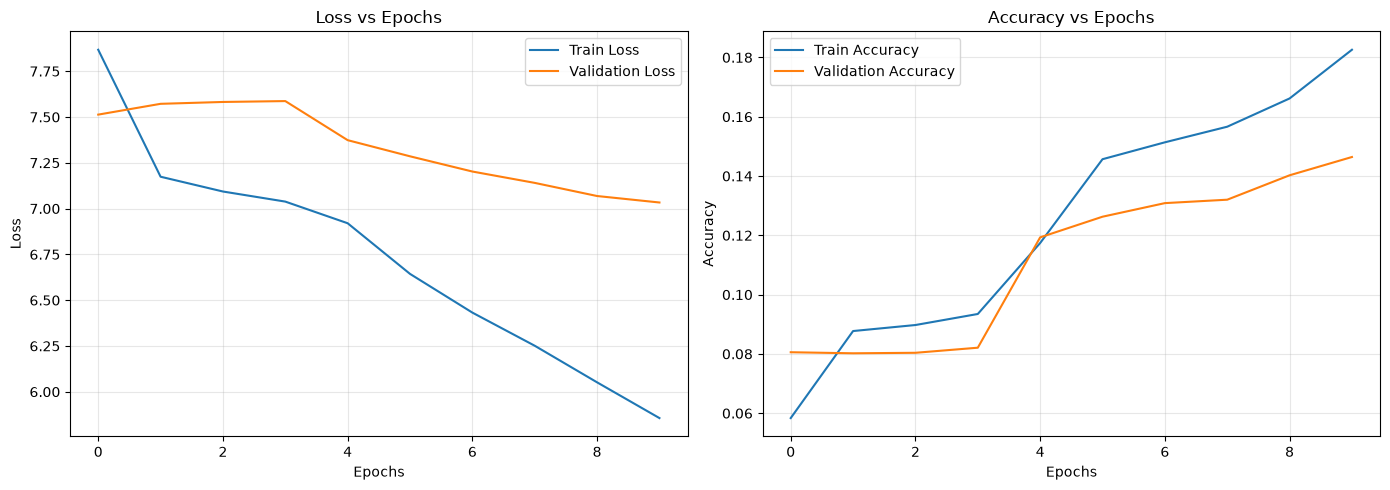

In [37]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss
axes[0].plot(history.history['loss'], label='Train Loss')
axes[0].plot(history.history['val_loss'], label='Validation Loss')
axes[0].set_title('Loss vs Epochs')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Accuracy
axes[1].plot(history.history['accuracy'], label='Train Accuracy')
axes[1].plot(history.history['val_accuracy'], label='Validation Accuracy')
axes[1].set_title('Accuracy vs Epochs')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Save the fitted model and the tokenizer




In [38]:
import pickle

model.save("seq2seq_deep_lstm.keras")

# Max Length 60
with open("eng_tokenizer.pkl", "wb") as f:
    pickle.dump(eng_tokenizer, f)

with open("fre_tokenizer.pkl", "wb") as f:
    pickle.dump(fre_tokenizer, f)
    
    
    

## Load the model


In [39]:
# Load trained model
model = tf.keras.models.load_model(
    "seq2seq_deep_lstm.keras"
)

# Load English tokenizer
with open("eng_tokenizer.pkl", "rb") as f:
    eng_tokenizer = pickle.load(f)

# Load French tokenizer
with open("fre_tokenizer.pkl", "rb") as f:
    fre_tokenizer = pickle.load(f)

# Load sequence lengths
# with open("seq2seq_config.pkl", "rb") as f:
#     config = pickle.load(f)

# max_len_eng = config["max_len_eng"]
# max_len_fre = config["max_len_fre"]

# Reverse French vocabulary mapping
fre_index_word = {
    index: word
    for word, index in fre_tokenizer.word_index.items()
}

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input_layer │ (None, 93)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_input_layer │ (None, 102)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_embedding_… │ (None, 93, 128)   │  2,906,112 │ encoder_input_la… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 93)        │          0 │ encoder_input_la… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_embedding_… │ (None, 102, 128)  │  3,344,640 │ decoder_input_la… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_lstm_layer1 │ [(None, 93, 128), │    131,584 │ encoder_embeddin… │
│ (LSTM)              │ (None, 128),      │            │ not_equal[0][0]   │
│                     │ (None, 128)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm_layer1 │ [(None, 102,      │    131,584 │ decoder_embeddin… │
│ (LSTM)              │ 128), (None,      │            │ encoder_lstm_lay… │
│                     │ 128), (None,      │            │ encoder_lstm_lay… │
│                     │ 128)]             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_lstm_layer2 │ [(None, 128),     │    131,584 │ encoder_lstm_lay… │
│ (LSTM)              │ (None, 128),      │            │ not_equal[0][0]   │
│                     │ (None, 128)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm_layer2 │ [(None, 102,      │    131,584 │ decoder_lstm_lay… │
│ (LSTM)              │ 128), (None,      │            │ encoder_lstm_lay… │
│                     │ 128), (None,      │            │ encoder_lstm_lay… │
│                     │ 128)]             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 102,       │  3,370,770 │ decoder_lstm_lay… │
│                     │ 26130)            │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 30,443,576 (116.13 MB)

 Trainable params: 10,147,858 (38.71 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 20,295,718 (77.42 MB)

In [40]:
#Dictionary comprehension to create a mapping from index to word for English vocabulary 
eng_index_word = {
    v : k for k, v in eng_tokenizer.word_index.items() # reverse the key-value pairs in the word_index dictionary to create a mapping from index to word
}

fre_index_word = {
    v : k for k, v in fre_tokenizer.word_index.items() # reverse the key-value pairs in the word_index dictionary to create a mapping from index to word
}
eng_index_word

{1: '<OOV>',
 2: 'the',
 3: 'of',
 4: 'and',
 5: 'in',
 6: 'to',
 7: 'a',
 8: 'is',
 9: 'for',
 10: 'are',
 11: 'that',
 12: 'as',
 13: 'with',
 14: 'on',
 15: 'from',
 16: 'by',
 17: 'at',
 18: 'this',
 19: 'canadian',
 20: 'be',
 21: 'was',
 22: 'food',
 23: 'an',
 24: 'has',
 25: 'it',
 26: 'or',
 27: ':',
 28: 'canada',
 29: 'market',
 30: 'have',
 31: 'he',
 32: 'its',
 33: 'trade',
 34: '•',
 35: 'products',
 36: 'which',
 37: 'more',
 38: 'their',
 39: 'also',
 40: 'not',
 41: 'million',
 42: 'will',
 43: '-',
 44: 'other',
 45: 'light',
 46: 'first',
 47: 'his',
 48: 'were',
 49: 'all',
 50: 'exports',
 51: 'new',
 52: 'agri-food',
 53: 'than',
 54: 'one',
 55: 'israel',
 56: 'international',
 57: 'over',
 58: 'imports',
 59: 'these',
 60: 'observatory',
 61: 'most',
 62: 'meat',
 63: 'can',
 64: 'been',
 65: 'government',
 66: 'growth',
 67: 'about',
 68: 'there',
 69: 'research',
 70: 'population',
 71: 'industry',
 72: 'into',
 73: 'information',
 74: 'agricultural',
 75: 'b

In [41]:
fre_tokenizer.word_index

{'<OOV>': 1,
 'de': 2,
 '<sos>': 3,
 '<eos>': 4,
 'la': 5,
 'et': 6,
 'les': 7,
 'des': 8,
 'le': 9,
 'à': 10,
 'en': 11,
 'du': 12,
 'pour': 13,
 ':': 14,
 'est': 15,
 'au': 16,
 'dans': 17,
 'un': 18,
 'une': 19,
 'que': 20,
 'qui': 21,
 'plus': 22,
 'sur': 23,
 'par': 24,
 'produits': 25,
 'a': 26,
 'sont': 27,
 'il': 28,
 'aux': 29,
 'ce': 30,
 'se': 31,
 'canada': 32,
 '%': 33,
 'ou': 34,
 'ont': 35,
 'avec': 36,
 'marché': 37,
 'pays': 38,
 'millions': 39,
 'son': 40,
 '«': 41,
 '•': 42,
 'comme': 43,
 'cette': 44,
 'pas': 45,
 'ces': 46,
 'on': 47,
 'ne': 48,
 'exportations': 49,
 'secteur': 50,
 'ses': 51,
 '-': 52,
 'sa': 53,
 'être': 54,
 'leur': 55,
 'entreprises': 56,
 'très': 57,
 'aliments': 58,
 'importations': 59,
 'entre': 60,
 'y': 61,
 'dollars': 62,
 'deux': 63,
 'mais': 64,
 'été': 65,
 'lumière': 66,
 'leurs': 67,
 'fait': 68,
 'production': 69,
 'commerce': 70,
 'dont': 71,
 "d'un": 72,
 'même': 73,
 'croissance': 74,
 'astronomes': 75,
 'valeur': 76,
 'aussi': 7

In [42]:
# translation
def translate_Sentence(sentence):
    ## step1 -> convert english sentence into neumerical values
    seq = eng_tokenizer.texts_to_sequences([sentence])
    
    # Step 2: Check whether words were recognized
    if len(seq[0]) == 0:
        return "Input sentence contains no known English words."
    
    ## step3 -> apply padding
    seq = pad_sequences(seq,
                        maxlen=max_len_eng,
                        padding='post'
                        )
    ## Step4 -> Get the start and end token ids
    start_token = fre_tokenizer.word_index['<sos>']
    end_token = fre_tokenizer.word_index['<eos>']
    
    ## Step5 -> start decoder with <sos>
    decoder_sequence = [start_token]
    
    translated_sentence = []
    
    ##step5 -> predict one word at a time
    for i in range(max_len_fre -1): # -1 because we don't want to predict the <sos> token
        decoder_input = pad_sequences([decoder_sequence],
                                        maxlen=max_len_fre,
                                        padding='post'
                                        )
        prediction = model.predict(
            [seq,decoder_input],
            verbose=0
        )
        
        ## Get the word ID with the highest probability
        
        next_word_id = np.argmax(prediction[0, len(decoder_sequence)-1, :])
        
        ## stop if the end token is predicted or padding token is predicted
        if next_word_id == end_token or next_word_id == 0:
            break
        
        ## Convert the neumerical id to french word
        translated_word = fre_index_word[next_word_id]
        translated_sentence.append(translated_word)
        
        ## add the predicted word to the decoder input for the next iteration
        decoder_sequence.append(next_word_id)
        
    return ' '.join(translated_sentence)      

In [43]:
sentence = "Good Morning"
translated_sentence = translate_Sentence(sentence)
print(f"English: {sentence}")
print(f"French: {translated_sentence}")

English: Good Morning
French: •


In [44]:
test_sentences = [
    "I am happy.",
    "I love you.",
    "How are you?",
    "Good Morning!",
    "Thank you"
]

for sentence in test_sentences:
    print(f"English: {sentence}")
    print(f"French: {translate_Sentence(sentence)}")
    print("-" * 40)

English: I am happy.
French: océan
----------------------------------------
English: I love you.
French: e
----------------------------------------
English: How are you?
French: variétés
----------------------------------------
English: Good Morning!
French: :
----------------------------------------
English: Thank you
French: 
----------------------------------------
